In [1]:

!pip -q install shap onnxmltools onnxruntime skl2onnx lightgbm xgboost catboost fastapi httpx joblib

In [2]:
import os, time, json, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_predict, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (classification_report, precision_recall_curve, auc, confusion_matrix,
                             roc_auc_score, brier_score_loss, f1_score, average_precision_score)
from sklearn.calibration import calibration_curve
from sklearn.base import clone

import lightgbm as lgb
import shap
import joblib

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
SEED = 42
np.random.seed(SEED)

In [3]:
CSV = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
URL = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
USING_SYNTHETIC = False
df = None

if os.path.exists(CSV):
    df = pd.read_csv(CSV)
else:
    try:
        urllib.request.urlretrieve(URL, CSV)
        df = pd.read_csv(CSV)
    except Exception as e:
        print('Не удалось скачать датасет:', e)

if df is None:
    # Синтетический аналог (со связью признаков и оттока), только для демонстрации
    USING_SYNTHETIC = True
    rng = np.random.default_rng(SEED)
    n = 3000
    tenure = rng.integers(1, 72, n)
    monthly = rng.uniform(20, 120, n)
    contract = rng.choice(['Month-to-month', 'One year', 'Two year'], n, p=[0.55, 0.21, 0.24])
    internet = rng.choice(['DSL', 'Fiber optic', 'No'], n, p=[0.35, 0.45, 0.20])
    payment = rng.choice(['Electronic check', 'Mailed check', 'Bank transfer'], n)
    logit = (-0.6 - 0.04 * tenure + 0.02 * (monthly - 65) + 1.2 * (contract == 'Month-to-month')
             + 0.6 * (internet == 'Fiber optic') + 0.5 * (payment == 'Electronic check'))
    churn = rng.random(n) < 1 / (1 + np.exp(-logit))
    df = pd.DataFrame({
        'tenure': tenure, 'MonthlyCharges': monthly,
        'TotalCharges': tenure * monthly * rng.uniform(0.9, 1.1, n),
        'Contract': contract, 'InternetService': internet, 'PaymentMethod': payment,
        'Churn': np.where(churn, 'Yes', 'No')})
    print('Создан синтетический аналог для демонстрации.')

print(f'Датасет: {df.shape[0]} строк, {df.shape[1]} столбцов')
print("Целевая переменная 'Churn':", df['Churn'].value_counts().to_dict())
df.head()

Датасет: 7043 строк, 21 столбцов
Целевая переменная 'Churn': {'No': 5174, 'Yes': 1869}


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Краткий EDA

object     18
int64       2
float64     1
Name: count, dtype: int64 

Пропусков/нечисловых значений в TotalCharges: 11


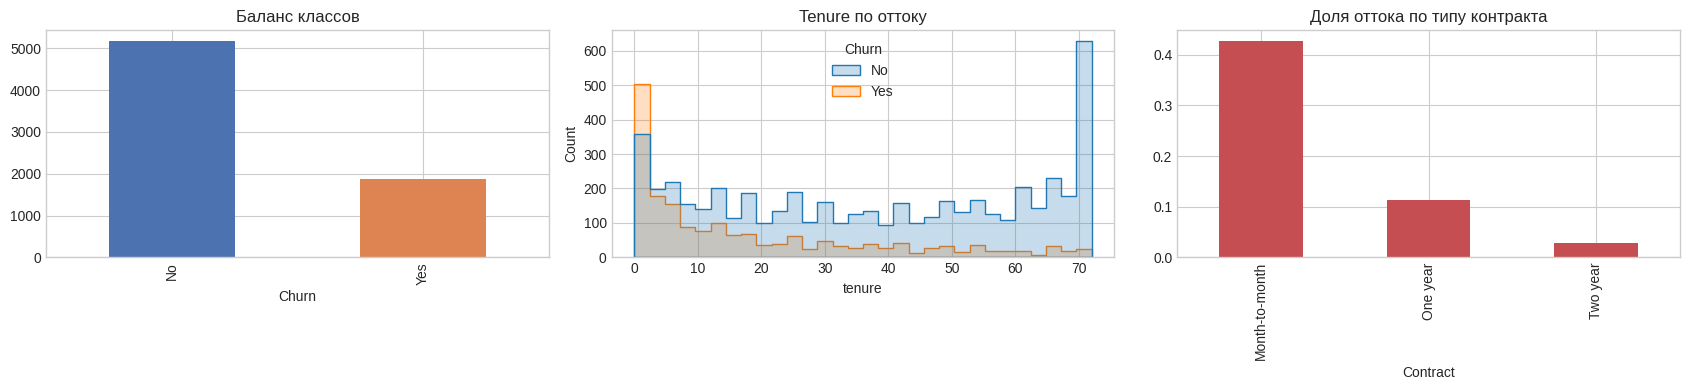

In [4]:
print(df.dtypes.value_counts(), '\n')
# В Telco TotalCharges содержит пустые строки " " у новых клиентов (tenure = 0)
tc = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Пропусков/нечисловых значений в TotalCharges:', tc.isna().sum())

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
df['Churn'].value_counts().plot.bar(ax=ax[0], color=['#4c72b0', '#dd8452'])
ax[0].set_title('Баланс классов')
sns.histplot(data=df, x='tenure', hue='Churn', bins=30, ax=ax[1], element='step')
ax[1].set_title('Tenure по оттоку')
if 'Contract' in df:
    (df.groupby('Contract')['Churn'].apply(lambda s: (s == 'Yes').mean())
       .plot.bar(ax=ax[2], color='#c44e52'))
    ax[2].set_title('Доля оттока по типу контракта')
plt.tight_layout(); plt.show()

## 3. Предобработка

* `TotalCharges` → число, строки с пропусками удаляем (их ~11, это новые клиенты).
* `customerID` удаляем (идентификатор, не признак).
* Разбиение train/test **со стратификацией**, `ColumnTransformer` обучается **только на train**.

In [5]:
df = df.copy()
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Удаляем строк с пропусками:', df.isna().any(axis=1).sum())
df = df.dropna().reset_index(drop=True)

X = df.drop(columns=['customerID', 'Churn'], errors='ignore')
y = (df['Churn'] == 'Yes').astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)

numeric_features = X.select_dtypes(include='number').columns.tolist()
categorical_features = X.select_dtypes(include='object').columns.tolist()
print('Числовые:', numeric_features)
print('Категориальные:', categorical_features)

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)])

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()
print(f'Train: {X_train_prep.shape}, Test: {X_test_prep.shape}')
print(f'Доля оттока: train={y_train.mean():.3f}, test={y_test.mean():.3f}')

Удаляем строк с пропусками: 11
Числовые: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Категориальные: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Train: (5625, 45), Test: (1407, 45)
Доля оттока: train=0.266, test=0.266


In [6]:
# Хелпер для единообразной оценки моделей
results = []

def evaluate(name, y_true, proba, thr=0.5):
    prec, rec, _ = precision_recall_curve(y_true, proba)
    row = {'model': name,
           'ROC-AUC': roc_auc_score(y_true, proba),
           'PR-AUC': auc(rec, prec),
           'AP': average_precision_score(y_true, proba),
           'Brier': brier_score_loss(y_true, proba),
           f'F1@{thr}': f1_score(y_true, (proba >= thr).astype(int))}
    results.append(row)
    return row

## 4. Baseline: Logistic Regression

In [7]:
baseline = LogisticRegression(max_iter=1000, random_state=SEED)
baseline.fit(X_train_prep, y_train)
y_pred_base = baseline.predict(X_test_prep)
y_proba_base = baseline.predict_proba(X_test_prep)[:, 1]

print('Baseline (Logistic Regression):')
print(classification_report(y_test, y_pred_base, target_names=['No Churn', 'Churn']))
r = evaluate('LogReg', y_test, y_proba_base)
print(f"ROC-AUC: {r['ROC-AUC']:.3f} | PR-AUC: {r['PR-AUC']:.3f} | Brier: {r['Brier']:.3f}")

Baseline (Logistic Regression):
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1033
       Churn       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407

ROC-AUC: 0.836 | PR-AUC: 0.621 | Brier: 0.140


## 5. Бустинг: LightGBM + подбор гиперпараметров

In [8]:
lgb_model = lgb.LGBMClassifier(random_state=SEED, verbose=-1)
param_grid = {'n_estimators': [50, 100, 200],
              'max_depth': [3, 5],
              'learning_rate': [0.03, 0.05, 0.1]}

grid = GridSearchCV(lgb_model, param_grid, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                    scoring='roc_auc', n_jobs=-1)
grid.fit(X_train_prep, y_train)

best_lgb = grid.best_estimator_
y_pred_lgb = best_lgb.predict(X_test_prep)
y_proba_lgb = best_lgb.predict_proba(X_test_prep)[:, 1]

print('Лучшие параметры:', grid.best_params_, f'| CV ROC-AUC = {grid.best_score_:.3f}')
print('\nLightGBM (Tuned):')
print(classification_report(y_test, y_pred_lgb, target_names=['No Churn', 'Churn']))
r = evaluate('LightGBM', y_test, y_proba_lgb)
print(f"ROC-AUC: {r['ROC-AUC']:.3f} | PR-AUC: {r['PR-AUC']:.3f} | Brier: {r['Brier']:.3f}")

Лучшие параметры: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 50} | CV ROC-AUC = 0.850

LightGBM (Tuned):
              precision    recall  f1-score   support

    No Churn       0.84      0.89      0.86      1033
       Churn       0.64      0.52      0.57       374

    accuracy                           0.79      1407
   macro avg       0.74      0.70      0.72      1407
weighted avg       0.78      0.79      0.79      1407

ROC-AUC: 0.839 | PR-AUC: 0.653 | Brier: 0.138


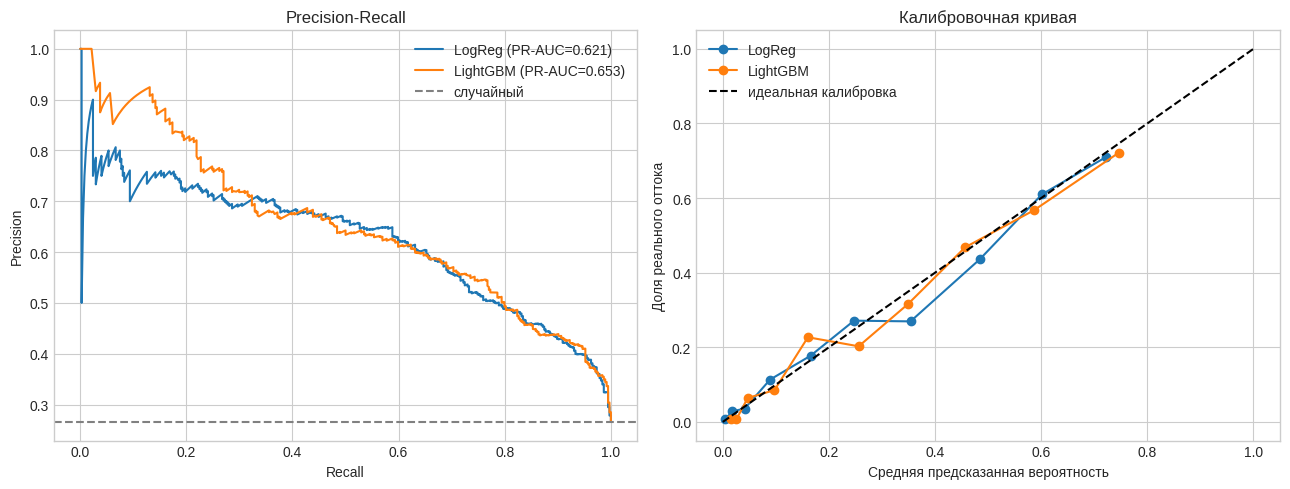

,model,ROC-AUC,PR-AUC,AP,Brier,F1@0.5
0,LogReg,0.8359,0.6213,0.6228,0.1401,0.6080
1,LightGBM,0.8394,0.6525,0.6528,0.1384,0.5702


In [9]:
# Сравнение моделей: PR-кривые и калибровка
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, p in [('LogReg', y_proba_base), ('LightGBM', y_proba_lgb)]:
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax[0].plot(rc, pr, label=f'{name} (PR-AUC={auc(rc, pr):.3f})')
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy='quantile')
    ax[1].plot(mean_pred, frac_pos, marker='o', label=name)
ax[0].axhline(y_test.mean(), color='gray', ls='--', label='случайный')
ax[0].set_xlabel('Recall'); ax[0].set_ylabel('Precision'); ax[0].set_title('Precision-Recall'); ax[0].legend()
ax[1].plot([0, 1], [0, 1], 'k--', label='идеальная калибровка')
ax[1].set_xlabel('Средняя предсказанная вероятность'); ax[1].set_ylabel('Доля реального оттока')
ax[1].set_title('Калибровочная кривая'); ax[1].legend()
plt.tight_layout(); plt.show()
pd.DataFrame(results).round(4)

## 6. Бизнес-порог

Стоимость: упущенный клиент (**FN**) = 5 000 ₽, лишнее удержание (**FP**) = 200 ₽.

Важно: порог подбираем на **OOF-предсказаниях train** (кросс-валидация), а test используем только для финальной честной оценки. Подбор порога прямо на test это утечка.

Оптимальный порог по бизнес-стоимости (по OOF train): 0.05

Стоимость на test (всего, ₽):
  порог 0.05 (бизнес)      :    163,000
  порог 0.50 (по умолчанию)       :    927,000
  «ничего не делать» (все FN)     :  1,870,000
  «удерживать всех» (все FP)      :    206,600


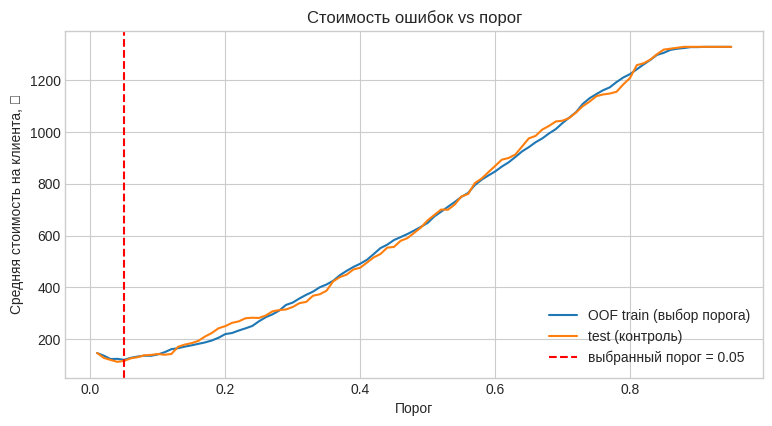


Classification Report (бизнес-порог):
              precision    recall  f1-score   support

    No Churn       0.98      0.36      0.52      1033
       Churn       0.36      0.98      0.52       374

    accuracy                           0.52      1407
   macro avg       0.67      0.67      0.52      1407
weighted avg       0.82      0.52      0.52      1407



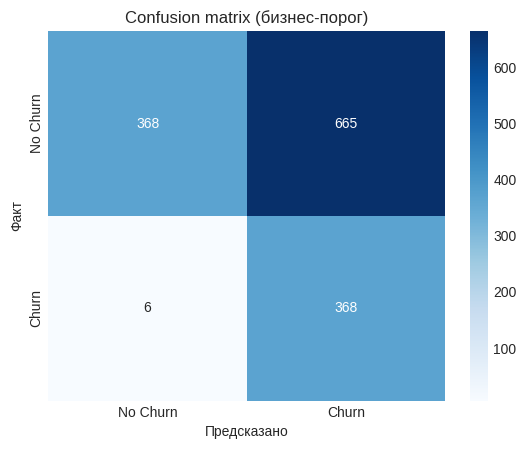

In [10]:
COST_FN, COST_FP = 5000, 200
y_tr, y_te = y_train.values, y_test.values

skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
oof_proba = cross_val_predict(clone(best_lgb), X_train_prep, y_tr, cv=skf, method='predict_proba')[:, 1]

thresholds = np.linspace(0.01, 0.95, 95)

def total_cost(y_true, proba, t):
    pred = proba >= t
    fn = ((y_true == 1) & ~pred).sum()
    fp = ((y_true == 0) & pred).sum()
    return fn * COST_FN + fp * COST_FP

cost_oof = np.array([total_cost(y_tr, oof_proba, t) for t in thresholds]) / len(y_tr)
cost_test = np.array([total_cost(y_te, y_proba_lgb, t) for t in thresholds]) / len(y_te)

best_t = float(thresholds[np.argmin(cost_oof)])
y_pred_business = (y_proba_lgb >= best_t).astype(int)
print(f'Оптимальный порог по бизнес-стоимости (по OOF train): {best_t:.2f}')

cost_at = lambda t: total_cost(y_te, y_proba_lgb, t)
print(f'\nСтоимость на test (всего, ₽):')
print(f'  порог {best_t:.2f} (бизнес)      : {cost_at(best_t):>10,.0f}')
print(f'  порог 0.50 (по умолчанию)       : {cost_at(0.5):>10,.0f}')
print(f'  «ничего не делать» (все FN)     : {y_te.sum() * COST_FN:>10,.0f}')
print(f'  «удерживать всех» (все FP)      : {(y_te == 0).sum() * COST_FP:>10,.0f}')

plt.figure(figsize=(9, 4.5))
plt.plot(thresholds, cost_oof, label='OOF train (выбор порога)')
plt.plot(thresholds, cost_test, label='test (контроль)')
plt.axvline(best_t, color='r', ls='--', label=f'выбранный порог = {best_t:.2f}')
plt.xlabel('Порог'); plt.ylabel('Средняя стоимость на клиента, ₽'); plt.legend(); plt.title('Стоимость ошибок vs порог')
plt.show()

print('\nClassification Report (бизнес-порог):')
print(classification_report(y_test, y_pred_business, target_names=['No Churn', 'Churn']))
sns.heatmap(confusion_matrix(y_test, y_pred_business), annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
plt.xlabel('Предсказано'); plt.ylabel('Факт'); plt.title('Confusion matrix (бизнес-порог)'); plt.show()

## 7. SHAP-интерпретация

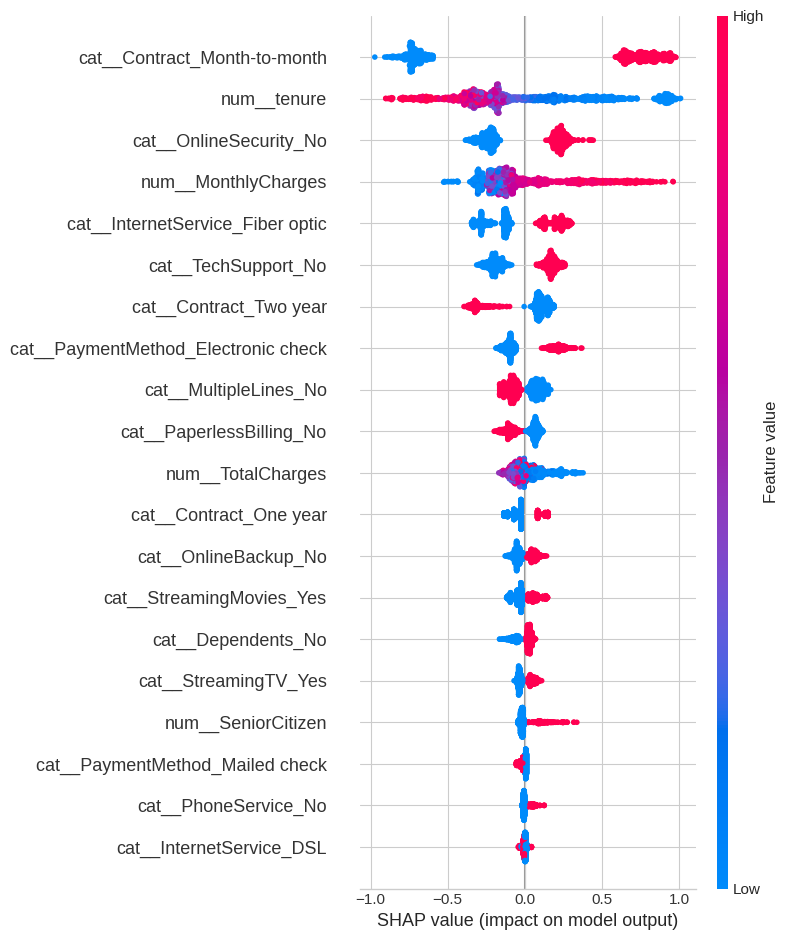

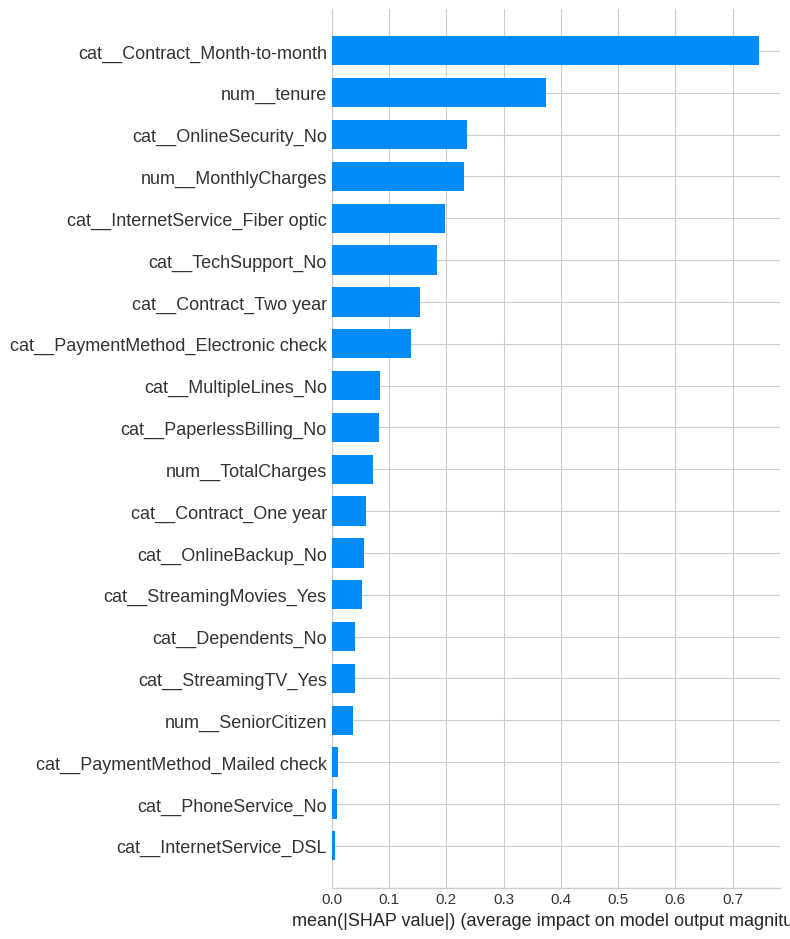

Топ-5 факторов для клиента #0 (P(churn) = 0.028):
cat__Contract_Month-to-month   -0.690
num__tenure                    -0.471
cat__Contract_Two year         -0.321
cat__OnlineSecurity_No          0.277
cat__TechSupport_No            -0.206
dtype: float64


In [11]:
explainer = shap.TreeExplainer(best_lgb)
shap_values = explainer.shap_values(X_test_prep)

# Разные версии shap возвращают разные форматы для бинарной классификации
if isinstance(shap_values, list):
    shap_values_to_plot = shap_values[1]          # класс Churn
elif getattr(shap_values, 'ndim', 2) == 3:
    shap_values_to_plot = shap_values[:, :, 1]
else:
    shap_values_to_plot = shap_values

shap.summary_plot(shap_values_to_plot, X_test_prep, feature_names=feature_names, show=True)
shap.summary_plot(shap_values_to_plot, X_test_prep, feature_names=feature_names, plot_type='bar', show=True)

# Локальное объяснение для одного клиента
i = 0
contrib = pd.Series(shap_values_to_plot[i], index=feature_names).sort_values(key=abs, ascending=False).head(5)
print(f'Топ-5 факторов для клиента #{i} (P(churn) = {y_proba_lgb[i]:.3f}):')
print(contrib.round(3))

## 8. Экспорт в ONNX

In [12]:
from onnxmltools.convert import convert_lightgbm
from onnxmltools.convert.common.data_types import FloatTensorType

n_features = X_train_prep.shape[1]
initial_type = [('float_input', FloatTensorType([None, n_features]))]
try:
    onnx_model = convert_lightgbm(best_lgb, initial_types=initial_type, zipmap=False)
except TypeError:  # старые версии onnxmltools не знают параметр zipmap
    onnx_model = convert_lightgbm(best_lgb, initial_types=initial_type)

with open('churn_model.onnx', 'wb') as f:
    f.write(onnx_model.SerializeToString())
print('Модель экспортирована в churn_model.onnx')

Модель экспортирована в churn_model.onnx


In [13]:
import onnxruntime as ort

def onnx_proba(sess, X):
    # Возвращает P(churn). Учитывает, что у классификатора два выхода: label и probabilities
    outs = sess.run(None, {sess.get_inputs()[0].name: np.asarray(X, dtype=np.float32)})
    for o in outs:
        if isinstance(o, np.ndarray) and o.ndim == 2 and o.shape[1] == 2:
            return o[:, 1]
        if isinstance(o, list) and len(o) and isinstance(o[0], dict):
            return np.array([d[sorted(d.keys())[-1]] for d in o])
    raise RuntimeError('Не найден выход с вероятностями')

session = ort.InferenceSession('churn_model.onnx', providers=['CPUExecutionProvider'])
input_name = session.get_inputs()[0].name
print('Входы :', [(i.name, i.shape) for i in session.get_inputs()])
print('Выходы:', [(o.name, o.shape) for o in session.get_outputs()])

proba_onnx_all = onnx_proba(session, X_test_prep)
print(f'\nМакс. расхождение ONNX vs LightGBM: {np.abs(proba_onnx_all - y_proba_lgb).max():.2e}')
print(f'Тестовый прогноз (ONNX), клиент #0: P(churn) = {proba_onnx_all[0]:.3f}')

Входы : [('float_input', [None, 45])]
Выходы: [('label', [1]), ('probabilities', [None, 2])]

Макс. расхождение ONNX vs LightGBM: 1.29e-07
Тестовый прогноз (ONNX), клиент #0: P(churn) = 0.028


## 9. Бенчмарк инференса (ONNX Runtime vs LightGBM sklearn API)

In [14]:
def bench(fn, n=200, warmup=10):
    for _ in range(warmup):
        fn()
    t0 = time.perf_counter()
    for _ in range(n):
        fn()
    return (time.perf_counter() - t0) / n * 1000  # мс

x1 = X_test_prep[:1].astype(np.float32)
xb = X_test_prep[:1000].astype(np.float32)

onnx_1 = bench(lambda: session.run(None, {input_name: x1}))
sk_1 = bench(lambda: best_lgb.predict_proba(x1))
onnx_b = bench(lambda: session.run(None, {input_name: xb}), n=50)
sk_b = bench(lambda: best_lgb.predict_proba(xb), n=50)

print('Среднее время инференса:')
print(f'  1 объект   | ONNX: {onnx_1:.3f} мс | LightGBM: {sk_1:.3f} мс | ускорение: {sk_1 / onnx_1:.1f}x')
print(f'  батч {len(xb)} | ONNX: {onnx_b:.3f} мс | LightGBM: {sk_b:.3f} мс | ускорение: {sk_b / onnx_b:.1f}x')
bench_store = {'LightGBM': {'onnx_ms_1': onnx_1, 'native_ms_1': sk_1}}

Среднее время инференса:
  1 объект   | ONNX: 0.029 мс | LightGBM: 1.286 мс | ускорение: 44.9x
  батч 1000 | ONNX: 2.869 мс | LightGBM: 4.468 мс | ускорение: 1.6x


## 10. Мониторинг дрейфа: PSI

Правило: PSI < 0.1 стабильно, 0.1–0.2 умеренный сдвиг, **> 0.2 сигнал к переобучению**. В проде вместо ручного расчёта можно использовать [Evidently AI](https://www.evidentlyai.com/), он строит такие отчёты автоматически.

In [15]:
def psi(expected, actual, bins=10):
    expected, actual = np.asarray(expected, float), np.asarray(actual, float)
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.clip(np.histogram(expected, edges)[0] / len(expected), 1e-4, None)
    a = np.clip(np.histogram(actual, edges)[0] / len(actual), 1e-4, None)
    return float(np.sum((a - e) * np.log(a / e)))

# 1) Реальное сравнение train vs test (дрейфа быть не должно)
rows = [{'feature': c, 'PSI train→test': psi(X_train[c], X_test[c])} for c in numeric_features]
rows.append({'feature': 'score (P churn)', 'PSI train→test': psi(oof_proba, y_proba_lgb)})

# 2) Симулируем дрейф: цены выросли, клиенты «моложе»
X_drift = X_test.copy()
if 'MonthlyCharges' in X_drift: X_drift['MonthlyCharges'] *= 1.3
if 'tenure' in X_drift: X_drift['tenure'] = (X_drift['tenure'] - 12).clip(lower=0)
proba_drift = best_lgb.predict_proba(preprocessor.transform(X_drift))[:, 1]
drift_map = {r['feature']: psi(X_train[r['feature']], X_drift[r['feature']]) for r in rows[:-1]}
drift_map['score (P churn)'] = psi(oof_proba, proba_drift)
psi_df = pd.DataFrame(rows)
psi_df['PSI симулированный дрейф'] = psi_df['feature'].map(drift_map)
psi_df['Нужно переобучение?'] = np.where(psi_df['PSI симулированный дрейф'] > 0.2, 'ДА (>0.2)', 'нет')
psi_df.round(4)

,feature,PSI train→test,PSI симулированный дрейф,Нужно переобучение?
0,SeniorCitizen,0.0000,0.0000,нет
1,tenure,0.0091,1.8439,ДА (>0.2)
2,MonthlyCharges,0.0108,1.4412,ДА (>0.2)
3,TotalCharges,0.0050,0.0050,нет
4,score (P churn),0.0131,0.1176,нет


## 11. Мини-сервис на FastAPI

Сервис принимает **сырые** признаки клиента (как в исходной таблице), применяет сохранённый препроцессор, считает вероятность через ONNX и сравнивает с бизнес-порогом.

In [16]:
# Артефакты для сервиса
joblib.dump(preprocessor, 'preprocessor.joblib')
with open('service_config.json', 'w') as f:
    json.dump({'columns': list(X.columns), 'threshold': best_t}, f, ensure_ascii=False, indent=2)
print('Сохранено: churn_model.onnx, preprocessor.joblib, service_config.json')

Сохранено: churn_model.onnx, preprocessor.joblib, service_config.json


In [17]:
%%writefile app.py
import json
from typing import Any, Dict

import joblib
import numpy as np
import onnxruntime as ort
import pandas as pd
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel

app = FastAPI(title="Churn Prediction API")

cfg = json.load(open("service_config.json"))
preprocessor = joblib.load("preprocessor.joblib")
session = ort.InferenceSession("churn_model.onnx", providers=["CPUExecutionProvider"])
input_name = session.get_inputs()[0].name


def onnx_proba(X):
    outs = session.run(None, {input_name: np.asarray(X, dtype=np.float32)})
    for o in outs:
        if isinstance(o, np.ndarray) and o.ndim == 2 and o.shape[1] == 2:
            return o[:, 1]
        if isinstance(o, list) and len(o) and isinstance(o[0], dict):
            return np.array([d[sorted(d.keys())[-1]] for d in o])
    raise RuntimeError("probabilities output not found")


class Customer(BaseModel):
    features: Dict[str, Any]


@app.get("/health")
def health():
    return {"status": "ok"}


@app.post("/predict")
def predict(req: Customer):
    missing = [c for c in cfg["columns"] if c not in req.features]
    if missing:
        raise HTTPException(status_code=422, detail=f"Missing features: {missing}")
    df = pd.DataFrame([req.features])[cfg["columns"]]
    proba = float(onnx_proba(preprocessor.transform(df))[0])
    return {"churn_probability": proba,
            "churn": proba >= cfg["threshold"],
            "threshold": cfg["threshold"]}

Writing app.py


In [18]:
# Тест сервиса прямо в ноутбуке (без запуска uvicorn)
import sys, importlib
sys.path.insert(0, os.getcwd())
import app as churn_app
importlib.reload(churn_app)
from fastapi.testclient import TestClient

client = TestClient(churn_app.app)
payload = {'features': json.loads(X_test.iloc[[0]].to_json(orient='records'))[0]}
resp = client.post('/predict', json=payload)
print('Статус:', resp.status_code)
print('Ответ :', resp.json())
print(f'Прямой ONNX-прогноз: {proba_onnx_all[0]:.4f} (должен совпасть)')
print('Проверка ошибки (пустые признаки):', client.post('/predict', json={'features': {}}).status_code)
# Локальный запуск вне Colab:  uvicorn app:app --reload

Статус: 200
Ответ : {'churn_probability': 0.027574539184570312, 'churn': False, 'threshold': 0.05}
Прямой ONNX-прогноз: 0.0276 (должен совпасть)
Проверка ошибки (пустые признаки): 422


## 12. Бонус: XGBoost и CatBoost
Сравнение с LightGBM по **PR-AUC, Brier Score и времени инференса в ONNX**.

In [19]:
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

cv3 = StratifiedKFold(3, shuffle=True, random_state=SEED)

xgb_grid = GridSearchCV(
    XGBClassifier(random_state=SEED, eval_metric='logloss', tree_method='hist'),
    {'n_estimators': [100, 200], 'max_depth': [3, 5], 'learning_rate': [0.05, 0.1]},
    cv=cv3, scoring='roc_auc', n_jobs=-1).fit(X_train_prep, y_train)
best_xgb = xgb_grid.best_estimator_
print('XGBoost  лучшие параметры:', xgb_grid.best_params_)

cat_grid = GridSearchCV(
    CatBoostClassifier(random_seed=SEED, verbose=0, thread_count=-1),
    {'iterations': [200, 400], 'depth': [4, 6], 'learning_rate': [0.05, 0.1]},
    cv=cv3, scoring='roc_auc', n_jobs=1).fit(X_train_prep, y_train)
best_cat = cat_grid.best_estimator_
print('CatBoost лучшие параметры:', cat_grid.best_params_)

proba_xgb = best_xgb.predict_proba(X_test_prep)[:, 1]
proba_cat = best_cat.predict_proba(X_test_prep)[:, 1]
evaluate('XGBoost', y_test, proba_xgb)
evaluate('CatBoost', y_test, proba_cat)

XGBoost  лучшие параметры: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}
CatBoost лучшие параметры: {'depth': 4, 'iterations': 200, 'learning_rate': 0.05}


{'model': 'CatBoost',
 'ROC-AUC': np.float64(0.8383556537989657),
 'PR-AUC': np.float64(0.6570063109556656),
 'AP': np.float64(0.657634167630531),
 'Brier': np.float64(0.13855206380052346),
 'F1@0.5': 0.5842026825633383}

In [20]:
# Экспорт XGBoost и CatBoost в ONNX и замер инференса
from onnxmltools.convert import convert_xgboost

sessions = {'LightGBM': session}
native_fn = {'LightGBM': lambda: best_lgb.predict_proba(x1)}
native_fn['XGBoost'] = lambda: best_xgb.predict_proba(x1)
native_fn['CatBoost'] = lambda: best_cat.predict_proba(x1)

try:
    m = convert_xgboost(best_xgb, initial_types=initial_type)
    open('churn_xgboost.onnx', 'wb').write(m.SerializeToString())
    sessions['XGBoost'] = ort.InferenceSession('churn_xgboost.onnx', providers=['CPUExecutionProvider'])
except Exception as e:
    print('XGBoost -> ONNX не удалось:', repr(e)[:300])

try:
    best_cat.save_model('churn_catboost.onnx', format='onnx')
    sessions['CatBoost'] = ort.InferenceSession('churn_catboost.onnx', providers=['CPUExecutionProvider'])
except Exception as e:
    print('CatBoost -> ONNX не удалось:', repr(e)[:300])

native_proba = {'LightGBM': y_proba_lgb, 'XGBoost': proba_xgb, 'CatBoost': proba_cat}
for name, sess in sessions.items():
    iname = sess.get_inputs()[0].name
    t_onnx = bench(lambda: sess.run(None, {iname: x1}))
    t_nat = bench(native_fn[name])
    diff = np.abs(onnx_proba(sess, X_test_prep) - native_proba[name]).max()
    bench_store[name] = {'onnx_ms_1': t_onnx, 'native_ms_1': t_nat, 'max_diff': diff}
    print(f'{name:9s} | ONNX {t_onnx:.3f} мс | native {t_nat:.3f} мс | расхождение {diff:.1e}')

LightGBM  | ONNX 0.009 мс | native 0.628 мс | расхождение 1.3e-07
XGBoost   | ONNX 0.011 мс | native 0.298 мс | расхождение 1.8e-07
CatBoost  | ONNX 0.017 мс | native 0.314 мс | расхождение 2.3e-07


,ROC-AUC,PR-AUC,AP,Brier,F1@0.5,"ONNX, мс (1 объект)","native, мс (1 объект)"
model,,,,,,,
LogReg,0.8359,0.6213,0.6228,0.1401,0.6080,NaN,NaN
LightGBM,0.8394,0.6525,0.6528,0.1384,0.5702,0.0095,0.6282
XGBoost,0.8403,0.6558,0.6559,0.1381,0.5706,0.0106,0.2985
CatBoost,0.8384,0.6570,0.6576,0.1386,0.5842,0.0170,0.3137


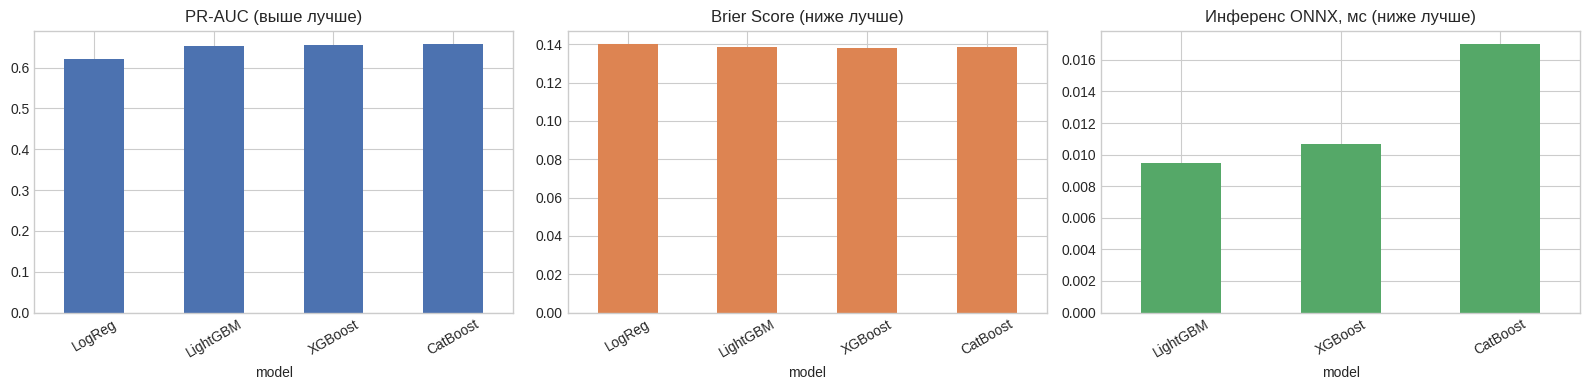

Лучший по PR-AUC: CatBoost | лучший по Brier: XGBoost


In [21]:
res = pd.DataFrame(results).set_index('model')
res['ONNX, мс (1 объект)'] = pd.Series({k: v['onnx_ms_1'] for k, v in bench_store.items()})
res['native, мс (1 объект)'] = pd.Series({k: v['native_ms_1'] for k, v in bench_store.items()})
display(res.round(4))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
res['PR-AUC'].plot.bar(ax=ax[0], color='#4c72b0', title='PR-AUC (выше лучше)')
res['Brier'].plot.bar(ax=ax[1], color='#dd8452', title='Brier Score (ниже лучше)')
res['ONNX, мс (1 объект)'].dropna().plot.bar(ax=ax[2], color='#55a868', title='Инференс ONNX, мс (ниже лучше)')
for a in ax: a.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

boost = res.loc[[m for m in ['LightGBM', 'XGBoost', 'CatBoost'] if m in res.index]]
print('Лучший по PR-AUC:', boost['PR-AUC'].idxmax(), '| лучший по Brier:', boost['Brier'].idxmin())